# Reconocimiento del Alfabeto Completo de Lengua de Señas Mexicana (LSM) con Landmarks 3D

Este notebook implementa y compara de forma reproducible los modelos de aprendizaje profundo para las **27 letras del alfabeto dactilológico de la LSM**:
- **21 señas estáticas** (`A, B, C, D, E, F, G, H, I, L, M, N, O, P, R, S, T, U, V, W, Y`) — fuente: *Mexican Sign Language Alphabet (static signs only)* ([Zenodo 10067509](https://zenodo.org/records/10067509), CC-BY-4.0, 279,716 imágenes de 20 participantes en 3 niveles de variación `A`, `B`, `C`).
- **6 señas dinámicas** (`J, K, Ñ, Q, X, Z`) — fuente: *Mexican Sign Language Alphabet (dynamic signs only)* ([Zenodo 14689869](https://zenodo.org/records/14689869), CC-BY-4.0, 1,242 clips de video en vista frontal y perfil 45° de 20 participantes).

### Compresión del dataset y división estricta por persona (0 fuga de datos)
En lugar de descargar ~8 GB en `.7z` (~25 GB descomprimidos), el repositorio incluye los **landmarks 3D extraídos con MediaPipe Hands (`0.10.21`)** en formato **Parquet ZSTD (~88 MB en total)** dentro de `data/hf_lsm_dataset/`. Los conjuntos de **entrenamiento, validación y prueba están separados estrictamente por sujeto** (`S18, S20` en prueba estática y `S20, S21` en prueba dinámica nunca vistos durante el entrenamiento).

### Modelos comparados en este notebook
1. **Estáticas (21 letras):** `MLP-Base` (ANN simple, 60 coordenadas crudas) vs **`HandGeoResNet`** (arquitectura residual sobre 184 features geométricas 3D + aumento 3D + Label Smoothing + Cosine Annealing).
   *(El experimento comparativo con CNN RGB `MobileNetV3-Small` sobre imágenes crudas se encuentra en `lsm/train_static_cnn.py`.)*
2. **Dinámicas (6 letras):** `LSTM-Base` (LSTM unidireccional sobre secuencia cruda 63D) vs **`DynamicBiGRUAttn`** (Bi-GRU de 2 capas + Atención Temporal sobre 214 features espaciotemporales).


In [1]:
# En Google Colab, si clonaste el repositorio primero:
# !git clone <URL_DE_TU_REPOSITORIO> && cd Proyecto_RNA
# Descomenta la siguiente línea si falta alguna dependencia:
# !pip install -q torch torchvision scikit-learn matplotlib pyarrow huggingface_hub

import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pyarrow.parquet as pq
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.metrics import classification_report, confusion_matrix, f1_score

# Fijar semilla global para reproducibilidad exacta de inicialización, batches y aumento 3D
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Dispositivo: {DEVICE}", f"({torch.cuda.get_device_name(0)})" if DEVICE == "cuda" else "")


Dispositivo: cuda (NVIDIA GeForce RTX 4050 Laptop GPU)


## 1. Carga del dataset ligero (Local Parquet o Hugging Face Hub)
Si clonaste el repositorio de GitHub (`data/hf_lsm_dataset/`), los archivos Parquet se leen directamente de disco sin descargas externas (~88 MB). Opcionalmente, si subiste el paquete a Hugging Face Datasets (`python lsm/prepare_hf_package.py --push-to ...`), puedes indicar tu repositorio en `HF_REPO_ID`.


In [2]:
# Dejar vacío para usar la copia local incluida en el repositorio (data/hf_lsm_dataset/)
HF_REPO_ID = ""
LOCAL_DIR = Path("data/hf_lsm_dataset")

def load_parquet_split(section: str, split: str):
    """Lee un split ('train', 'validation' o 'test') en Parquet ZSTD desde local o Hugging Face."""
    local_file = LOCAL_DIR / section / f"{split}.parquet"
    if local_file.exists():
        return pq.read_table(local_file)
    if not HF_REPO_ID:
        raise FileNotFoundError(
            f"No se encontró {local_file}. Ejecuta desde la raíz del repositorio o define HF_REPO_ID."
        )
    from huggingface_hub import hf_hub_download
    dl_path = hf_hub_download(repo_id=HF_REPO_ID, filename=f"{section}/{split}.parquet", repo_type="dataset")
    return pq.read_table(dl_path)

# Cargar los 3 splits estrictamente separados por persona para ambas tareas
st_tr_tbl = load_parquet_split("static", "train")
st_va_tbl = load_parquet_split("static", "validation")
st_te_tbl = load_parquet_split("static", "test")
print(f"Estático -> train: {st_tr_tbl.num_rows:,} | val: {st_va_tbl.num_rows:,} | test: {st_te_tbl.num_rows:,}")

dy_tr_tbl = load_parquet_split("dynamic", "train")
dy_va_tbl = load_parquet_split("dynamic", "validation")
dy_te_tbl = load_parquet_split("dynamic", "test")
print(f"Dinámico -> train: {dy_tr_tbl.num_rows:,} | val: {dy_va_tbl.num_rows:,} | test: {dy_te_tbl.num_rows:,}")


Estático -> train: 209,399 | val: 42,698 | test: 27,619


Dinámico -> train: 930 | val: 192 | test: 120


## 2. Preprocesamiento e Ingeniería Geométrica 3D (184 features)
- **Renormalización 3D:** centra la mano en la muñeca (`punto 0`) y escala por la distancia euclidiana 3D promedio hacia los nudillos `[5, 9, 13, 17]`, evitando distorsiones proyectivas cuando la mano apunta hacia la cámara.
- **Marco canónico de la palma:** construye una base ortonormal `[v_x, v_up, v_norm]` invariante a rotaciones 3D globales (yaw/pitch/roll), conservando al mismo tiempo la orientación absoluta de la palma `[v_up, v_norm]` (6D) para distinguir señas que solo cambian por giro (ej. `G` vs `H`, `U` vs `P`).
- **Descriptores geométricos discriminativos:** 15 ángulos de flexión intra-dedo, 8 ángulos de apertura interdigital, 23 distancias clave (muñeca-punta, entre puntas y pulgar-articulaciones) y 12 relaciones específicas para pares críticos (`R vs U`, `V vs U`, `M vs N`, `E vs S`).
- **Aumento de datos 3D realista:** rotaciones aleatorias yaw/pitch/roll, leve jitter de escala anisotrópico y ruido gaussiano **sin espejo horizontal** para no alterar la lateralidad de la LSM.


In [3]:
# Tripletas (a, b, c) para calcular el coseno del ángulo de flexión en la articulación b (15 ángulos)
FLEX_TRIPLETS = [
    (0, 1, 2), (1, 2, 3), (2, 3, 4),         # pulgar
    (0, 5, 6), (5, 6, 7), (6, 7, 8),         # índice
    (0, 9, 10), (9, 10, 11), (10, 11, 12),   # medio
    (0, 13, 14), (13, 14, 15), (14, 15, 16), # anular
    (0, 17, 18), (17, 18, 19), (18, 19, 20), # meñique
]
# Pares de huesos proximales adyacentes para abducción entre dedos (4 ángulos)
SPREAD_PAIRS = [((1, 2), (5, 6)), ((5, 6), (9, 10)), ((9, 10), (13, 14)), ((13, 14), (17, 18))]
FINGERTIPS = [4, 8, 12, 16, 20]
TIP_PAIRS = [(FINGERTIPS[i], FINGERTIPS[j]) for i in range(5) for j in range(i + 1, 5)]  # 10 pares
THUMB_TO_JOINTS = [(4, j) for j in (5, 6, 9, 10, 13, 14, 17, 18)]  # 8 pares clave (A/E/M/N/S/T)
PALM_ANCHORS = [5, 9, 13, 17]

FEATURE_DIM = 184
# Índices exactos de [v_up(3), v_norm(3)] dentro del vector de 184 features (60+60+15+4+5+10+8 = 162)
PALM_ORIENT_SLICE = slice(162, 168)


def renormalize_3d(pts: torch.Tensor) -> torch.Tensor:
    """Centra en la muñeca (punto 0) y escala por la distancia media 3D a los nudillos."""
    pts = pts - pts[:, 0:1, :]
    palm_dist = pts[:, PALM_ANCHORS, :].norm(dim=-1).mean(dim=-1, keepdim=True).unsqueeze(-1)
    return pts / palm_dist.clamp_min(1e-6)


def augment_hand_3d(pts: torch.Tensor, yaw=30.0, pitch=26.0, roll=22.0, noise=0.018, scale=0.10):
    """Aplica rotación 3D aleatoria (yaw/pitch/roll), variación de escala y ruido en GPU."""
    b, dev, dt = pts.shape[0], pts.device, pts.dtype
    rx = (torch.rand(b, device=dev, dtype=dt) * 2 - 1) * np.deg2rad(pitch)
    ry = (torch.rand(b, device=dev, dtype=dt) * 2 - 1) * np.deg2rad(yaw)
    rz = (torch.rand(b, device=dev, dtype=dt) * 2 - 1) * np.deg2rad(roll)
    cx, sx, cy, sy, cz, sz = torch.cos(rx), torch.sin(rx), torch.cos(ry), torch.sin(ry), torch.cos(rz), torch.sin(rz)
    z0, o1 = torch.zeros_like(cx), torch.ones_like(cx)

    Rx = torch.stack([o1, z0, z0, z0, cx, -sx, z0, sx, cx], -1).view(b, 3, 3)
    Ry = torch.stack([cy, z0, sy, z0, o1, z0, -sy, z0, cy], -1).view(b, 3, 3)
    Rz = torch.stack([cz, -sz, z0, sz, cz, z0, z0, z0, o1], -1).view(b, 3, 3)

    out = torch.bmm(pts, (Rz @ Ry @ Rx).transpose(1, 2))
    out = out * (1.0 + (torch.rand(b, 1, 3, device=dev, dtype=dt) * 2 - 1) * scale) + torch.randn_like(out) * noise
    return renormalize_3d(out)


def compute_hand_features(pts: torch.Tensor) -> torch.Tensor:
    """Transforma landmarks (B, 21, 3) en un descriptor geométrico invariante de 184 dimensiones."""
    pts = renormalize_3d(pts)
    b = pts.shape[0]
    # 1) Coordenadas normalizadas en cámara (60)
    view_coords = pts[:, 1:, :].reshape(b, 60)

    # 2) Marco canónico de la palma: proyecta la mano a su propia base ortonormal (60 + 6 orientación)
    v_up = F.normalize(pts[:, 9] - pts[:, 0], dim=-1, eps=1e-6)
    v_side = pts[:, 5] - pts[:, 17]
    v_norm = F.normalize(torch.linalg.cross(v_side, v_up, dim=-1), dim=-1, eps=1e-6)
    v_x = F.normalize(torch.linalg.cross(v_up, v_norm, dim=-1), dim=-1, eps=1e-6)
    R_palm = torch.stack([v_x, v_up, v_norm], dim=-1)
    palm_pts = torch.bmm(pts, R_palm)
    palm_coords = palm_pts[:, 1:, :].reshape(b, 60)
    palm_orient = torch.cat([v_up, v_norm], dim=-1)  # Índices [162:168]

    # 3) Cosenos de flexión intra-dedo (15)
    a_i = torch.tensor([t[0] for t in FLEX_TRIPLETS], device=pts.device)
    b_i = torch.tensor([t[1] for t in FLEX_TRIPLETS], device=pts.device)
    c_i = torch.tensor([t[2] for t in FLEX_TRIPLETS], device=pts.device)
    flex_cos = (F.normalize(pts[:, a_i] - pts[:, b_i], dim=-1, eps=1e-6) *
                F.normalize(pts[:, c_i] - pts[:, b_i], dim=-1, eps=1e-6)).sum(-1)

    # 4) Apertura entre dedos adyacentes: falanges proximales (4) y rayos nudillo->punta (4)
    s1 = F.normalize(torch.stack([pts[:, p[0][1]] - pts[:, p[0][0]] for p in SPREAD_PAIRS], 1), dim=-1, eps=1e-6)
    s2 = F.normalize(torch.stack([pts[:, p[1][1]] - pts[:, p[1][0]] for p in SPREAD_PAIRS], 1), dim=-1, eps=1e-6)
    spread_cos = (s1 * s2).sum(-1)

    rays_u = F.normalize(torch.stack([
        pts[:, 4] - pts[:, 1], pts[:, 8] - pts[:, 5], pts[:, 12] - pts[:, 9],
        pts[:, 16] - pts[:, 13], pts[:, 20] - pts[:, 17],
    ], 1), dim=-1, eps=1e-6)
    ray_spread = (rays_u[:, :-1] * rays_u[:, 1:]).sum(-1)

    # 5) Distancias clave (5 punta-muñeca + 10 entre puntas + 8 pulgar-articulaciones = 23)
    tip_wrist = pts[:, FINGERTIPS, :].norm(dim=-1)
    t_i = torch.tensor([p[0] for p in TIP_PAIRS], device=pts.device)
    t_j = torch.tensor([p[1] for p in TIP_PAIRS], device=pts.device)
    tip_dist = (pts[:, t_i] - pts[:, t_j]).norm(dim=-1)
    th_i = torch.tensor([p[0] for p in THUMB_TO_JOINTS], device=pts.device)
    th_j = torch.tensor([p[1] for p in THUMB_TO_JOINTS], device=pts.device)
    thumb_dist = (pts[:, th_i] - pts[:, th_j]).norm(dim=-1)

    # 6) Descriptores específicos para pares fácilmente confundibles (U/V/R, M/N, E/S)
    ratio_8_12 = (pts[:, 8] - pts[:, 12]).norm(dim=-1) / (pts[:, 5] - pts[:, 9]).norm(dim=-1).clamp_min(1e-4)
    ratio_12_16 = (pts[:, 12] - pts[:, 16]).norm(dim=-1) / (pts[:, 9] - pts[:, 13]).norm(dim=-1).clamp_min(1e-4)
    ratio_16_20 = (pts[:, 16] - pts[:, 20]).norm(dim=-1) / (pts[:, 13] - pts[:, 17]).norm(dim=-1).clamp_min(1e-4)
    cross_ru = (torch.linalg.cross(rays_u[:, 1], rays_u[:, 2], dim=-1) * v_norm).sum(-1)
    lat_8_12 = palm_pts[:, 8, 0] - palm_pts[:, 12, 0]
    ring_vs_mid_y = palm_pts[:, 16, 1] - palm_pts[:, 12, 1]
    ring_vs_mid_z = palm_pts[:, 16, 2] - palm_pts[:, 12, 2]
    thumb_z = palm_pts[:, 4, 2]
    tip_to_mid_mcp = (pts[:, [8, 12, 16, 20]] - pts[:, 9:10]).norm(dim=-1)

    extra = torch.cat([
        ray_spread,
        torch.stack([ratio_8_12, ratio_12_16, ratio_16_20, cross_ru, lat_8_12,
                     ring_vs_mid_y, ring_vs_mid_z, thumb_z], -1),
        tip_to_mid_mcp,
    ], -1)
    return torch.cat([view_coords, palm_coords, flex_cos, spread_cos, tip_wrist, tip_dist, thumb_dist, palm_orient, extra], -1)


## 3. Parte A — Entrenamiento y comparación de señas estáticas (21 letras)
Se filtran únicamente las muestras donde MediaPipe no detectó mano (`detected == False`, ~1.05% en prueba) para evitar entrenar sobre vectores en cero. En la evaluación final reportamos tanto la **exactitud condicional sobre detecciones** como la **exactitud efectiva sobre el 100% de las imágenes** (donde las no-detecciones cuentan como error) para una comparación justa por subconjunto (`A`, `B`, `C`).


In [4]:
def extract_static_tensors(tbl, cls_to_idx=None):
    """Filtra muestras detectadas por MediaPipe y convierte columnas PyArrow a arreglos NumPy."""
    det = tbl["detected"].to_numpy(zero_copy_only=False).astype(bool)
    vecs = np.vstack(tbl["landmarks"].to_numpy(zero_copy_only=False)).reshape(-1, 21, 3).astype(np.float32)
    labs = tbl["label"].to_numpy(zero_copy_only=False).astype(str)
    subs = tbl["subset"].to_numpy(zero_copy_only=False).astype(str)
    if cls_to_idx is None:
        classes = sorted({str(v) for v in labs})
        cls_to_idx = {c: i for i, c in enumerate(classes)}
    else:
        classes = sorted(cls_to_idx, key=cls_to_idx.get)
    y = np.array([cls_to_idx[str(v)] for v in labs], dtype=np.int64)
    return vecs[det], y[det], subs[det], det, subs, classes, cls_to_idx


Xtr_s, ytr_s, _, det_tr_s, _, static_classes, s_c2i = extract_static_tensors(st_tr_tbl)
Xva_s, yva_s, _, _, _, _, _ = extract_static_tensors(st_va_tbl, s_c2i)
Xte_s, yte_s, sub_te_det, det_te_s, sub_te_all, _, _ = extract_static_tensors(st_te_tbl, s_c2i)

# Pre-cargar tensores en el dispositivo (GPU/CPU) acelera significativamente las épocas
Xtr_st = torch.tensor(Xtr_s, device=DEVICE); ytr_st = torch.tensor(ytr_s, device=DEVICE)
Xva_st = torch.tensor(Xva_s, device=DEVICE); yva_st = torch.tensor(yva_s, device=DEVICE)
Xte_st = torch.tensor(Xte_s, device=DEVICE); yte_st = torch.tensor(yte_s, device=DEVICE)
print(f"Limpios -> train: {len(Xtr_st):,} | val: {len(Xva_st):,} | test detectado: {len(Xte_st):,}/{len(det_te_s):,} (det={det_te_s.mean():.2%})")


class MLPBase(nn.Module):
    """Modelo base (ANN): perceptrón multicapa sobre las 60 coordenadas 3D normalizadas."""
    def __init__(self, n_cls, hidden=(256, 128), p=0.25):
        super().__init__()
        layers, d = [], 60
        for h in hidden:
            layers += [nn.Linear(d, h), nn.BatchNorm1d(h), nn.ReLU(), nn.Dropout(p)]
            d = h
        layers.append(nn.Linear(d, n_cls))
        self.net = nn.Sequential(*layers)

    def forward(self, pts):
        return self.net(renormalize_3d(pts)[:, 1:, :].reshape(pts.shape[0], 60))


class ResBlock(nn.Module):
    """Bloque residual con Pre-LayerNorm, activación GELU y doble Dropout."""
    def __init__(self, dim, p=0.32):
        super().__init__()
        self.block = nn.Sequential(
            nn.LayerNorm(dim), nn.Linear(dim, dim), nn.GELU(), nn.Dropout(p),
            nn.Linear(dim, dim), nn.Dropout(p),
        )

    def forward(self, x):
        return x + self.block(x)


class HandGeoResNet(nn.Module):
    """Arquitectura avanzada: red residual regularizada sobre 184 features geométricas 3D."""
    def __init__(self, n_cls, width=256, n_blocks=2, p=0.32):
        super().__init__()
        self.stem = nn.Sequential(nn.BatchNorm1d(FEATURE_DIM), nn.Linear(FEATURE_DIM, width), nn.GELU())
        self.blocks = nn.Sequential(*[ResBlock(width, p=p) for _ in range(n_blocks)])
        self.head = nn.Sequential(nn.LayerNorm(width), nn.Dropout(p * 0.5), nn.Linear(width, n_cls))

    def forward(self, pts):
        return self.head(self.blocks(self.stem(compute_hand_features(pts))))


def fit_static(name, model, lr, epochs=60, batch=512, patience=14, aug3d=False, ls=0.0, wd=2e-4, cosine=False):
    """Entrena un modelo estático con AdamW, scheduler, gradient clipping y early stopping por Macro-F1."""
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    steps = epochs * ((len(Xtr_st) + batch - 1) // batch)
    sched = (torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=steps, eta_min=lr * 0.01) if cosine
             else torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=steps))
    lossf = nn.CrossEntropyLoss(label_smoothing=ls)
    best_f1, best_ep, best_state, bad = -1.0, 0, None, 0
    hist = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": [], "val_f1": []}

    for ep in range(1, epochs + 1):
        model.train()
        perm = torch.randperm(len(Xtr_st), device=DEVICE)
        tl, tc, ns = 0.0, 0, 0
        for i in range(0, len(perm), batch):
            b = perm[i:i + batch]
            if len(b) < 2:
                continue  # BatchNorm1d requiere al menos 2 muestras
            xb = augment_hand_3d(Xtr_st[b]) if aug3d else Xtr_st[b]
            yb = ytr_st[b]
            opt.zero_grad()
            lo = model(xb)
            loss = lossf(lo, yb)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 2.0)
            opt.step()
            sched.step()
            tl += loss.item() * len(b)
            tc += (lo.argmax(1) == yb).sum().item()
            ns += len(b)

        # Evaluación en validación (sujetos S5, S12, S17 no vistos)
        model.eval()
        with torch.no_grad():
            lo_v = torch.cat([model(Xva_st[i:i + 2048]) for i in range(0, len(Xva_st), 2048)])
            vl = lossf(lo_v, yva_st).item()
            vp = lo_v.argmax(1)
        vacc = float((vp == yva_st).float().mean())
        vf1 = float(f1_score(yva_st.cpu().numpy(), vp.cpu().numpy(), average="macro"))
        hist["train_loss"].append(tl / ns)
        hist["train_acc"].append(tc / ns)
        hist["val_loss"].append(vl)
        hist["val_acc"].append(vacc)
        hist["val_f1"].append(vf1)

        if ep == 1 or ep % 5 == 0 or vf1 > best_f1:
            print(f"[{name}] ep {ep:2d} | loss {tl/ns:.4f} acc {tc/ns:.4f} | val_loss {vl:.4f} val_acc {vacc:.4f} val_f1 {vf1:.4f}")
        if vf1 > best_f1:
            best_f1, best_ep, bad = vf1, ep, 0
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= patience:
                print(f"[{name}] Early stopping en época {ep} (mejor: {best_ep}, val_f1={best_f1:.4f})")
                break

    model.load_state_dict({k: v.to(DEVICE) for k, v in best_state.items()})
    return model, hist, best_f1, best_ep


# Semilla fijada justo antes de instanciar ambos modelos para reproducibilidad bit-a-bit
torch.manual_seed(SEED)
np.random.seed(SEED)
mlp_model, h_mlp, bf1_mlp, bep_mlp = fit_static(
    "MLP-Base", MLPBase(len(static_classes)).to(DEVICE), lr=2e-3, aug3d=False
)
geo_model, h_geo, bf1_geo, bep_geo = fit_static(
    "HandGeoResNet", HandGeoResNet(len(static_classes)).to(DEVICE),
    lr=1e-3, aug3d=True, ls=0.05, wd=1e-3, cosine=True
)


Limpios -> train: 206,478 | val: 42,409 | test detectado: 27,329/27,619 (det=98.95%)


[MLP-Base] ep  1 | loss 1.7229 acc 0.5984 | val_loss 0.8496 val_acc 0.8701 val_f1 0.8658


[MLP-Base] ep  2 | loss 0.6461 acc 0.8639 | val_loss 0.3580 val_acc 0.9259 val_f1 0.9257


[MLP-Base] ep  3 | loss 0.3375 acc 0.9163 | val_loss 0.2043 val_acc 0.9481 val_f1 0.9480


[MLP-Base] ep  4 | loss 0.2155 acc 0.9399 | val_loss 0.1507 val_acc 0.9534 val_f1 0.9534


[MLP-Base] ep  5 | loss 0.1524 acc 0.9553 | val_loss 0.1256 val_acc 0.9591 val_f1 0.9590


... (12 outputs left out)

[HandGeoResNet] ep 10 | loss 0.3653 acc 0.9902 | val_loss 0.4396 val_acc 0.9745 val_f1 0.9744


[HandGeoResNet] ep 15 | loss 0.3589 acc 0.9924 | val_loss 0.4476 val_acc 0.9720 val_f1 0.9718


[HandGeoResNet] ep 20 | loss 0.3552 acc 0.9939 | val_loss 0.4569 val_acc 0.9708 val_f1 0.9706


[HandGeoResNet] Early stopping en época 24 (mejor: 10, val_f1=0.9744)


=== TEST MLP-Base === Acc detectado: 0.9384 | Acc efectiva (100%): 0.9285 | Macro-F1: 0.9385 | Det: 98.95%
  Subconjuntos (detectado) -> A=0.9938 | B=0.9526 | C=0.8670
  Subconjuntos (efectiva)  -> A=0.9917 | B=0.9510 | C=0.8433


=== TEST HandGeoResNet === Acc detectado: 0.9592 | Acc efectiva (100%): 0.9492 | Macro-F1: 0.9586 | Det: 98.95%
  Subconjuntos (detectado) -> A=0.9988 | B=0.9746 | C=0.9032
  Subconjuntos (efectiva)  -> A=0.9967 | B=0.9730 | C=0.8786

Reporte por letra (HandGeoResNet):
              precision    recall  f1-score   support

           A     0.9640    0.9817    0.9728      1419
           B     0.9800    0.9579    0.9688      1331
           C     0.9968    0.9738    0.9852      1299
           D     0.9925    0.9748    0.9836      1350
           E     0.9585    0.9308    0.9444      1315
           F     0.9741    0.9713    0.9727      1394
           G     0.9748    0.9470    0.9607      1227
           H     0.9532    0.9723    0.9627      1300
           I     0.9362    0.9637    0.9498      1324
           L     0.9839    0.9948    0.9894      1355
           M     0.9616    0.8700    0.9135      1238
           N     0.8854    0.9626    0.9224      1284
           O     0.9811    

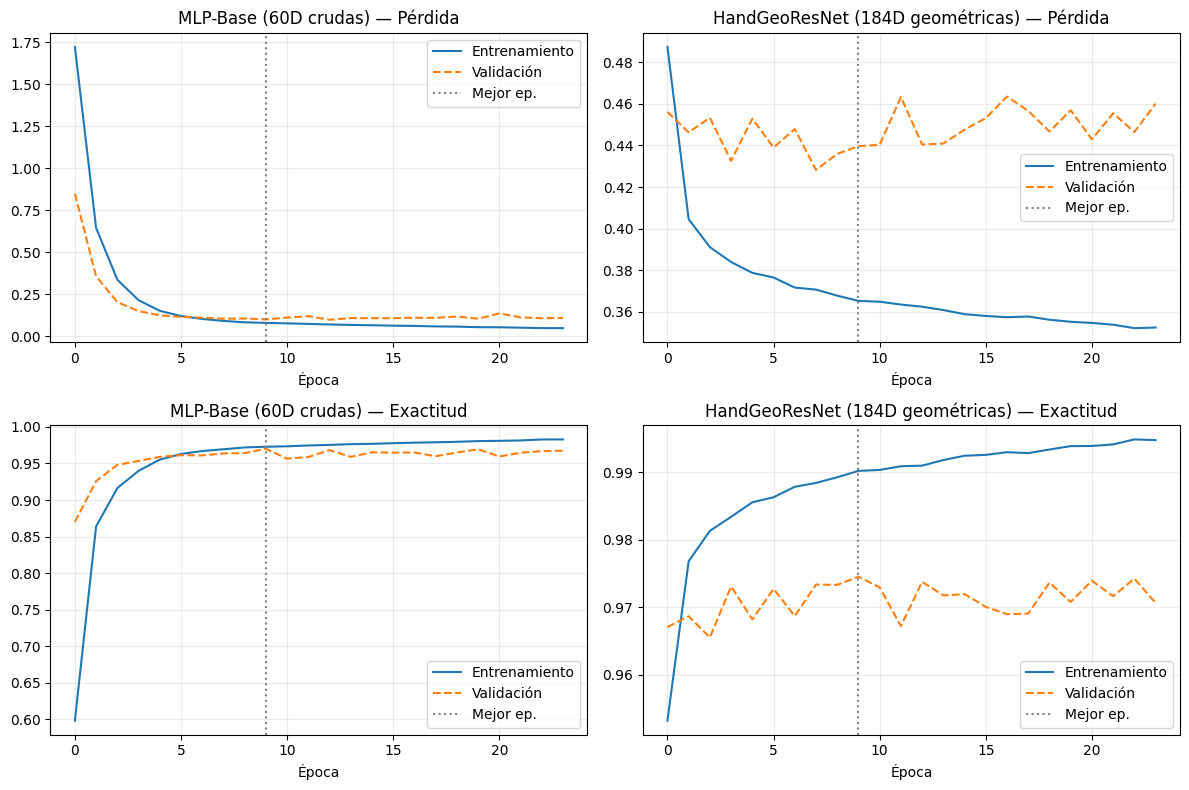

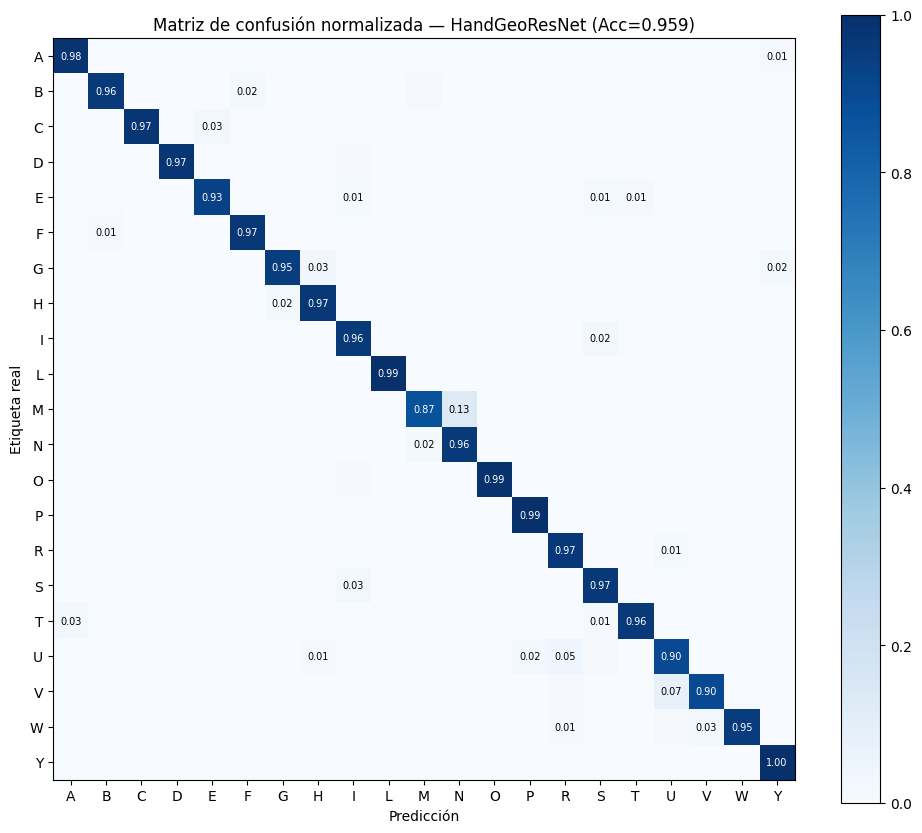

In [5]:
def eval_static_model(name, model):
    """Evalúa en el conjunto de prueba (S18, S20) reportando métricas detectadas y efectivas."""
    model.eval()
    with torch.no_grad():
        yp = torch.cat([model(Xte_st[i:i + 2048]).argmax(1) for i in range(0, len(Xte_st), 2048)]).cpu().numpy()
    yt = yte_s
    acc = float((yt == yp).mean())
    det_rate = float(det_te_s.mean())
    eff_acc = acc * det_rate
    f1m = float(f1_score(yt, yp, average="macro"))

    sub_acc, sub_eff = {}, {}
    for s in ("A", "B", "C"):
        ms = sub_te_det == s
        ms_all = sub_te_all == s
        s_acc = float((yt[ms] == yp[ms]).mean())
        s_det = float(det_te_s[ms_all].mean())
        sub_acc[s] = s_acc
        sub_eff[s] = s_acc * s_det

    print(
        f"=== TEST {name} === Acc detectado: {acc:.4f} | Acc efectiva (100%): {eff_acc:.4f} | "
        f"Macro-F1: {f1m:.4f} | Det: {det_rate:.2%}"
    )
    print(
        f"  Subconjuntos (detectado) -> A={sub_acc['A']:.4f} | B={sub_acc['B']:.4f} | C={sub_acc['C']:.4f}\n"
        f"  Subconjuntos (efectiva)  -> A={sub_eff['A']:.4f} | B={sub_eff['B']:.4f} | C={sub_eff['C']:.4f}"
    )
    return yp, acc, eff_acc, f1m, sub_acc, sub_eff


yp_mlp, acc_mlp, eff_mlp, f1_mlp, sub_mlp, sub_eff_mlp = eval_static_model("MLP-Base", mlp_model)
yp_geo, acc_geo, eff_geo, f1_geo, sub_geo, sub_eff_geo = eval_static_model("HandGeoResNet", geo_model)

print("\nReporte por letra (HandGeoResNet):")
print(classification_report(yte_s, yp_geo, target_names=static_classes, digits=4))

# Cuadrícula 2x2 de curvas de pérdida y exactitud (entrenamiento vs validación)
fig, ax = plt.subplots(2, 2, figsize=(12, 8))
for col, (t, h, bep) in enumerate([("MLP-Base (60D crudas)", h_mlp, bep_mlp), ("HandGeoResNet (184D geométricas)", h_geo, bep_geo)]):
    ax[0, col].plot(h["train_loss"], label="Entrenamiento")
    ax[0, col].plot(h["val_loss"], "--", label="Validación")
    ax[0, col].axvline(bep - 1, color="gray", ls=":", label="Mejor ep.")
    ax[0, col].set_title(f"{t} — Pérdida")
    ax[0, col].set_xlabel("Época")
    ax[0, col].legend()
    ax[0, col].grid(alpha=0.25)

    ax[1, col].plot(h["train_acc"], label="Entrenamiento")
    ax[1, col].plot(h["val_acc"], "--", label="Validación")
    ax[1, col].axvline(bep - 1, color="gray", ls=":", label="Mejor ep.")
    ax[1, col].set_title(f"{t} — Exactitud")
    ax[1, col].set_xlabel("Época")
    ax[1, col].legend()
    ax[1, col].grid(alpha=0.25)
plt.tight_layout()
plt.show()

# Matriz de confusión normalizada con anotaciones numéricas (>= 0.01)
cm_s = confusion_matrix(yte_s, yp_geo)
cm_sn = cm_s / cm_s.sum(1, keepdims=True)
fig, ax = plt.subplots(figsize=(10, 8.5))
im = ax.imshow(cm_sn, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(static_classes))); ax.set_xticklabels(static_classes)
ax.set_yticks(range(len(static_classes))); ax.set_yticklabels(static_classes)
ax.set_title(f"Matriz de confusión normalizada — HandGeoResNet (Acc={acc_geo:.3f})")
ax.set_xlabel("Predicción"); ax.set_ylabel("Etiqueta real")
for i in range(len(static_classes)):
    for j in range(len(static_classes)):
        val = cm_sn[i, j]
        if val >= 0.01:
            ax.text(j, i, f"{val:.2f}", ha="center", va="center", fontsize=7,
                    color="white" if val > 0.55 else "black")
plt.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()


## 4. Parte B — Señas Dinámicas (6 letras: J, K, Ñ, Q, X, Z)
Cada clip se recorta a su tramo con mano detectada, se interpolan huecos puntuales y se remuestrea a `T = 32` cuadros. Posteriormente se centra toda la trayectoria en el centroide de la muñeca del clip (conservando el desplazamiento espacial de `J, K, Ñ, Q, X, Z`) y se comparan **`LSTM-Base`** (secuencia cruda 63D) vs **`DynamicBiGRUAttn`** (Bi-GRU de 2 capas + Atención Temporal sobre 214 features espaciotemporales).


Dinámicos listos (['J', 'K', 'Q', 'X', 'Z', 'Ñ']) -> train: 930 | val: 192 | test: 120


[LSTM-Base] ep   1 | loss 1.7604 acc 0.2538 | val_loss 1.7384 val_acc 0.3385 val_f1 0.2846
[LSTM-Base] ep   2 | loss 1.7151 acc 0.4118 | val_loss 1.6991 val_acc 0.4635 val_f1 0.3897


[LSTM-Base] ep   3 | loss 1.6648 acc 0.4720 | val_loss 1.6536 val_acc 0.4948 val_f1 0.4300
[LSTM-Base] ep   4 | loss 1.6078 acc 0.4882 | val_loss 1.5965 val_acc 0.4844 val_f1 0.4321


[LSTM-Base] ep   5 | loss 1.5392 acc 0.5097 | val_loss 1.5180 val_acc 0.4844 val_f1 0.4336


[LSTM-Base] ep   7 | loss 1.3115 acc 0.5355 | val_loss 1.2850 val_acc 0.5260 val_f1 0.4891


[LSTM-Base] ep   9 | loss 1.0367 acc 0.6269 | val_loss 1.0454 val_acc 0.5781 val_f1 0.5587
[LSTM-Base] ep  10 | loss 0.9029 acc 0.6828 | val_loss 0.8941 val_acc 0.7240 val_f1 0.7097


... (29 outputs left out)

[DynamicBiGRUAttn] ep  33 | loss 0.2683 acc 1.0000 | val_loss 0.2530 val_acc 1.0000 val_f1 1.0000


[DynamicBiGRUAttn] ep  40 | loss 0.2556 acc 1.0000 | val_loss 0.2489 val_acc 1.0000 val_f1 1.0000


[DynamicBiGRUAttn] ep  50 | loss 0.2513 acc 1.0000 | val_loss 0.2451 val_acc 1.0000 val_f1 1.0000


[DynamicBiGRUAttn] Early stopping en época 58 (mejor: 33, val_f1=1.0000)
=== TEST DynamicBiGRUAttn === Acc: 1.0000 | Macro-F1: 1.0000 | Vistas: {np.str_('frontal'): 1.0, np.str_('profile'): 1.0}

Reporte Dinámico (DynamicBiGRUAttn):
              precision    recall  f1-score   support

           J     1.0000    1.0000    1.0000        20
           K     1.0000    1.0000    1.0000        20
           Q     1.0000    1.0000    1.0000        20
           X     1.0000    1.0000    1.0000        20
           Z     1.0000    1.0000    1.0000        20
           Ñ     1.0000    1.0000    1.0000        20

    accuracy                         1.0000       120
   macro avg     1.0000    1.0000    1.0000       120
weighted avg     1.0000    1.0000    1.0000       120



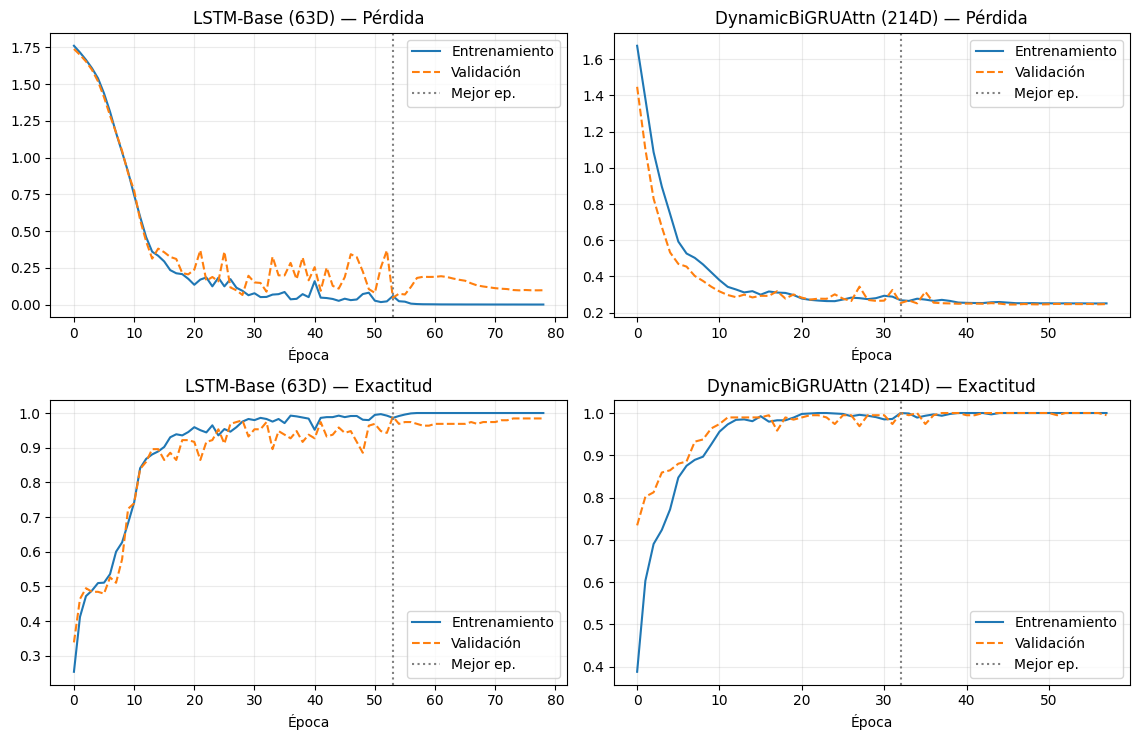

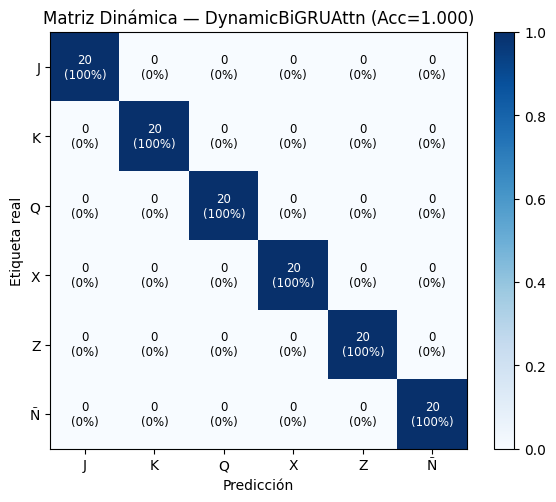

In [6]:
SEQ_LEN = 32
DYN_FEAT_DIM = FEATURE_DIM + 30  # 184 forma + 3 pos + 3 vel + 3 acel + 15 vel_puntas + 6 vel_orient = 214


def prepare_dynamic_split(tbl, cls_to_idx=None):
    """Interpola cuadros faltantes, remuestrea a SEQ_LEN=32 y normaliza trayectoria por clip."""
    seqs_raw = tbl["sequence"].to_numpy(zero_copy_only=False)
    dets_raw = tbl["detected"].to_numpy(zero_copy_only=False)
    labs = tbl["label"].to_numpy(zero_copy_only=False).astype(str)
    views = tbl["view"].to_numpy(zero_copy_only=False).astype(str)
    if cls_to_idx is None:
        classes = sorted({str(v) for v in labs})
        cls_to_idx = {c: i for i, c in enumerate(classes)}
    else:
        classes = sorted(cls_to_idx, key=cls_to_idx.get)

    X_out, y_out, v_out = [], [], []
    for s_flat, d_arr, lab, vw in zip(seqs_raw, dets_raw, labs, views):
        seq = np.asarray(s_flat, dtype=np.float32).reshape(-1, 21, 3)
        det = np.asarray(d_arr, dtype=bool)
        if len(seq) == 0 or det.sum() < 5:
            continue
        idx = np.where(det)[0]
        sub = seq[idx[0]:idx[-1] + 1].copy()
        sdet = det[idx[0]:idx[-1] + 1]
        t_all = np.arange(len(sub))
        if not sdet.all():
            for j in range(21):
                for c in range(3):
                    sub[:, j, c] = np.interp(t_all, t_all[sdet], sub[sdet, j, c])
        t_new = np.linspace(0, len(sub) - 1, SEQ_LEN)
        res = np.empty((SEQ_LEN, 21, 3), dtype=np.float32)
        for j in range(21):
            for c in range(3):
                res[:, j, c] = np.interp(t_new, t_all, sub[:, j, c])

        # Centrar en la muñeca promedio del clip y escalar por el tamaño mediano de la palma
        local = res - res[:, 0:1, :]
        med = float(np.median(np.linalg.norm(local[:, PALM_ANCHORS, :], axis=-1).mean(axis=-1)))
        res = (res - res[:, 0:1, :].mean(axis=0, keepdims=True)) / (med if med > 1e-6 else 1.0)
        X_out.append(res); y_out.append(cls_to_idx[str(lab)]); v_out.append(vw)
    return np.stack(X_out), np.array(y_out, dtype=np.int64), np.array(v_out), classes, cls_to_idx


Xtr_d, ytr_d, _, dyn_classes, d_c2i = prepare_dynamic_split(dy_tr_tbl)
Xva_d, yva_d, _, _, _ = prepare_dynamic_split(dy_va_tbl, d_c2i)
Xte_d, yte_d, vte_d, _, _ = prepare_dynamic_split(dy_te_tbl, d_c2i)

Xtr_dt = torch.tensor(Xtr_d, device=DEVICE); ytr_dt = torch.tensor(ytr_d, device=DEVICE)
Xva_dt = torch.tensor(Xva_d, device=DEVICE); yva_dt = torch.tensor(yva_d, device=DEVICE)
Xte_dt = torch.tensor(Xte_d, device=DEVICE); yte_dt = torch.tensor(yte_d, device=DEVICE)
print(f"Dinámicos listos ({dyn_classes}) -> train: {len(Xtr_dt)} | val: {len(Xva_dt)} | test: {len(Xte_dt)}")


def augment_dynamic_3d(seq):
    """Aumento espaciotemporal: recorte/estiramiento temporal + rotación 3D coherente + escala y ruido."""
    b, T, _, _ = seq.shape
    dev, dt = seq.device, seq.dtype
    out = seq.clone()
    for k in range(b):
        if torch.rand(1, device=dev).item() < 0.7:
            win = max(8, int(round(T * (0.80 + 0.20 * torch.rand(1, device=dev).item()))))
            start = int(torch.randint(0, T - win + 1, (1,), device=dev).item())
            crop = seq[k, start:start + win].permute(1, 2, 0).reshape(63, 1, win)
            res = F.interpolate(crop.unsqueeze(0), size=(1, T), mode="bilinear", align_corners=True)
            out[k] = res.squeeze(0).squeeze(1).permute(1, 0).reshape(T, 21, 3)

    rx = (torch.rand(b, device=dev, dtype=dt) * 2 - 1) * np.deg2rad(15.0)
    ry = (torch.rand(b, device=dev, dtype=dt) * 2 - 1) * np.deg2rad(20.0)
    rz = (torch.rand(b, device=dev, dtype=dt) * 2 - 1) * np.deg2rad(15.0)
    cx, sx, cy, sy, cz, sz = torch.cos(rx), torch.sin(rx), torch.cos(ry), torch.sin(ry), torch.cos(rz), torch.sin(rz)
    z0, o1 = torch.zeros_like(cx), torch.ones_like(cx)
    Rx = torch.stack([o1, z0, z0, z0, cx, -sx, z0, sx, cx], -1).view(b, 3, 3)
    Ry = torch.stack([cy, z0, sy, z0, o1, z0, -sy, z0, cy], -1).view(b, 3, 3)
    Rz = torch.stack([cz, -sz, z0, sz, cz, z0, z0, z0, o1], -1).view(b, 3, 3)
    R = (Rz @ Ry @ Rx).unsqueeze(1)
    out = torch.matmul(out, R.transpose(-1, -2)) * (1.0 + (torch.rand(b, 1, 1, 3, device=dev, dtype=dt) * 2 - 1) * 0.08)
    return out + torch.randn_like(out) * 0.01


def compute_dynamic_features(seq):
    """Calcula 214 features por paso temporal: forma 3D (184) + trayectoria/dinámica (30)."""
    b, T, _, _ = seq.shape
    shape = compute_hand_features(seq.reshape(b * T, 21, 3)).reshape(b, T, FEATURE_DIM)
    wrist = seq[:, :, 0, :]
    w_vel = F.pad(wrist[:, 1:] - wrist[:, :-1], (0, 0, 1, 0))
    w_acc = F.pad(w_vel[:, 1:] - w_vel[:, :-1], (0, 0, 1, 0))
    tips = seq[:, :, FINGERTIPS, :].reshape(b, T, 15)
    t_vel = F.pad(tips[:, 1:] - tips[:, :-1], (0, 0, 1, 0))
    orient = shape[:, :, PALM_ORIENT_SLICE]  # orientación real [v_up, v_norm] de la palma
    o_vel = F.pad(orient[:, 1:] - orient[:, :-1], (0, 0, 1, 0))
    return torch.cat([shape, wrist, w_vel, w_acc, t_vel, o_vel], dim=-1)


class LSTMBase(nn.Module):
    """Modelo base temporal: LSTM de 1 capa sobre coordenadas crudas (63D) por cuadro."""
    def __init__(self, n_cls, hidden=128, p=0.3):
        super().__init__()
        self.lstm = nn.LSTM(63, hidden, num_layers=1, batch_first=True)
        self.head = nn.Sequential(nn.Dropout(p), nn.Linear(hidden, n_cls))

    def forward(self, seq):
        out, _ = self.lstm(seq.reshape(seq.shape[0], seq.shape[1], 63))
        return self.head(out[:, -1, :])


class DynamicBiGRUAttn(nn.Module):
    """Modelo avanzado: Bi-GRU de 2 capas con Atención Temporal + MaxPooling sobre 214 features."""
    def __init__(self, n_cls, d_in=DYN_FEAT_DIM, d_model=160, hidden=128, p=0.3):
        super().__init__()
        self.proj = nn.Sequential(nn.LayerNorm(d_in), nn.Linear(d_in, d_model), nn.GELU(), nn.Dropout(p * 0.5))
        self.gru = nn.GRU(d_model, hidden, num_layers=2, batch_first=True, bidirectional=True, dropout=p)
        self.attn = nn.Sequential(nn.Linear(hidden * 2, 64), nn.Tanh(), nn.Linear(64, 1))
        self.head = nn.Sequential(
            nn.LayerNorm(hidden * 4), nn.Dropout(p), nn.Linear(hidden * 4, 128),
            nn.GELU(), nn.Dropout(p), nn.Linear(128, n_cls),
        )

    def forward(self, seq):
        h, _ = self.gru(self.proj(compute_dynamic_features(seq)))
        w = torch.softmax(self.attn(h), dim=1)
        return self.head(torch.cat([(h * w).sum(1), h.max(1).values], -1))


def fit_dynamic(name, model, epochs=140, batch=64, patience=25, aug=False, ls=0.0):
    """Entrena y evalúa un modelo secuencial registrando curvas de pérdida y exactitud."""
    opt = torch.optim.AdamW(model.parameters(), lr=2e-3, weight_decay=5e-4)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=2e-3, total_steps=epochs * ((len(Xtr_dt) + batch - 1) // batch))
    lossf = nn.CrossEntropyLoss(label_smoothing=ls)
    best_f1, best_ep, best_state, bad = -1.0, 0, None, 0
    hist = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": [], "val_f1": []}

    for ep in range(1, epochs + 1):
        model.train()
        perm = torch.randperm(len(Xtr_dt), device=DEVICE)
        tl, tc, ns = 0.0, 0, 0
        for i in range(0, len(perm), batch):
            b = perm[i:i + batch]
            if len(b) < 2:
                continue
            xb = augment_dynamic_3d(Xtr_dt[b]) if aug else Xtr_dt[b]
            yb = ytr_dt[b]
            opt.zero_grad()
            lo = model(xb)
            loss = lossf(lo, yb)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 2.0)
            opt.step()
            sched.step()
            tl += loss.item() * len(b)
            tc += (lo.argmax(1) == yb).sum().item()
            ns += len(b)

        model.eval()
        with torch.no_grad():
            lo_v = model(Xva_dt)
            vl = lossf(lo_v, yva_dt).item()
            vp = lo_v.argmax(1)
        vacc = float((vp == yva_dt).float().mean())
        vf1 = float(f1_score(yva_dt.cpu().numpy(), vp.cpu().numpy(), average="macro"))
        hist["train_loss"].append(tl / ns)
        hist["train_acc"].append(tc / ns)
        hist["val_loss"].append(vl)
        hist["val_acc"].append(vacc)
        hist["val_f1"].append(vf1)

        if ep == 1 or ep % 10 == 0 or vf1 > best_f1:
            print(f"[{name}] ep {ep:3d} | loss {tl/ns:.4f} acc {tc/ns:.4f} | val_loss {vl:.4f} val_acc {vacc:.4f} val_f1 {vf1:.4f}")
        if vf1 > best_f1:
            best_f1, best_ep, bad = vf1, ep, 0
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= patience:
                print(f"[{name}] Early stopping en época {ep} (mejor: {best_ep}, val_f1={best_f1:.4f})")
                break

    model.load_state_dict({k: v.to(DEVICE) for k, v in best_state.items()})
    model.eval()
    with torch.no_grad():
        yp = model(Xte_dt).argmax(1).cpu().numpy()
    acc = float((yte_d == yp).mean())
    f1m = float(f1_score(yte_d, yp, average="macro"))
    by_view = {vw: float((yte_d[vte_d == vw] == yp[vte_d == vw]).mean()) for vw in sorted(set(vte_d))}
    print(f"=== TEST {name} === Acc: {acc:.4f} | Macro-F1: {f1m:.4f} | Vistas: {by_view}")
    return model, hist, best_f1, best_ep, yp, acc, f1m


torch.manual_seed(SEED)
np.random.seed(SEED)
lstm_m, h_lstm, bf1_lstm, bep_lstm, yp_lstm, acc_lstm, f1_lstm = fit_dynamic(
    "LSTM-Base", LSTMBase(len(dyn_classes)).to(DEVICE), aug=False, ls=0.0
)
gru_m, h_gru, bf1_gru, bep_gru, yp_gru, acc_gru, f1_gru = fit_dynamic(
    "DynamicBiGRUAttn", DynamicBiGRUAttn(len(dyn_classes)).to(DEVICE), aug=True, ls=0.05
)

print("\nReporte Dinámico (DynamicBiGRUAttn):")
print(classification_report(yte_d, yp_gru, target_names=dyn_classes, digits=4))

# Cuadrícula 2x2 de curvas de entrenamiento/validación para señas dinámicas
fig, ax = plt.subplots(2, 2, figsize=(11.5, 7.5))
for col, (t, h, bep) in enumerate([("LSTM-Base (63D)", h_lstm, bep_lstm), ("DynamicBiGRUAttn (214D)", h_gru, bep_gru)]):
    ax[0, col].plot(h["train_loss"], label="Entrenamiento")
    ax[0, col].plot(h["val_loss"], "--", label="Validación")
    ax[0, col].axvline(bep - 1, color="gray", ls=":", label="Mejor ep.")
    ax[0, col].set_title(f"{t} — Pérdida")
    ax[0, col].set_xlabel("Época")
    ax[0, col].legend()
    ax[0, col].grid(alpha=0.25)

    ax[1, col].plot(h["train_acc"], label="Entrenamiento")
    ax[1, col].plot(h["val_acc"], "--", label="Validación")
    ax[1, col].axvline(bep - 1, color="gray", ls=":", label="Mejor ep.")
    ax[1, col].set_title(f"{t} — Exactitud")
    ax[1, col].set_xlabel("Época")
    ax[1, col].legend()
    ax[1, col].grid(alpha=0.25)
plt.tight_layout()
plt.show()

# Matriz de confusión dinámica con conteos y porcentajes
cm_d = confusion_matrix(yte_d, yp_gru)
cmn_d = cm_d / cm_d.sum(1, keepdims=True)
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(cmn_d, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(dyn_classes))); ax.set_xticklabels(dyn_classes)
ax.set_yticks(range(len(dyn_classes))); ax.set_yticklabels(dyn_classes)
ax.set_title(f"Matriz Dinámica — DynamicBiGRUAttn (Acc={acc_gru:.3f})")
ax.set_xlabel("Predicción"); ax.set_ylabel("Etiqueta real")
for i in range(len(dyn_classes)):
    for j in range(len(dyn_classes)):
        ax.text(j, i, f"{cm_d[i, j]}\n({cmn_d[i, j]:.0%})", ha="center", va="center",
                fontsize=8.5, color="white" if cmn_d[i, j] > 0.55 else "black")
plt.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()


## 5. Resumen comparativo final (27 letras LSM)
La tabla siguiente consolida las métricas obtenidas sobre sujetos nunca vistos (`S18, S20` en estáticas y `S20, S21` en dinámicas), diferenciando entre exactitud condicional (sobre detecciones de MediaPipe) y exactitud efectiva sobre el 100% de las muestras de prueba.
- **Para reproducir el modelo CNN RGB (`MobileNetV3-Small`)** sobre imágenes crudas de Zenodo: `python lsm/train_static_cnn.py`.
- **Para probar el reconocedor en tiempo real con cámara web en local:** `python lsm/demo_camera.py`.


In [7]:
def count_params(m):
    return sum(p.numel() for p in m.parameters())

summary_rows = [
    ("Estático (21)", "MLP-Base (60D)", count_params(mlp_model), bf1_mlp, acc_mlp, eff_mlp, f1_mlp),
    ("Estático (21)", "HandGeoResNet (184D)", count_params(geo_model), bf1_geo, acc_geo, eff_geo, f1_geo),
    ("Dinámico (6)", "LSTM-Base (63D)", count_params(lstm_m), bf1_lstm, acc_lstm, acc_lstm, f1_lstm),
    ("Dinámico (6)", "DynamicBiGRUAttn (214D)", count_params(gru_m), bf1_gru, acc_gru, acc_gru, f1_gru),
]

# Si existe el resultado guardado de la CNN RGB (lsm/train_static_cnn.py), incluirlo en la comparativa
cnn_json = Path("outputs/static_cnn/resultados.json")
if cnn_json.exists():
    cnn_res = json.loads(cnn_json.read_text(encoding="utf-8"))
    summary_rows.insert(
        1,
        (
            "Estático (21)",
            "MobileNetV3-Small (CNN RGB)*",
            cnn_res["params"],
            cnn_res["val_f1_macro"],
            cnn_res["test_accuracy"],
            cnn_res["test_accuracy"],
            cnn_res["test_f1_macro"],
        ),
    )

hdr = f"{'Tarea':<14} | {'Modelo':<29} | {'Params':>9} | {'Val F1':>7} | {'Acc Det':>8} | {'Acc Efec':>8} | {'Macro-F1':>8}"
print(hdr)
print("-" * len(hdr))
for tarea, mod, n_p, vf1, adet, aef, tf1 in summary_rows:
    print(f"{tarea:<14} | {mod:<29} | {n_p:>9,} | {vf1:>7.4f} | {adet:>8.4f} | {aef:>8.4f} | {tf1:>8.4f}")
if cnn_json.exists():
    print("\n*Nota: MobileNetV3-Small fue entrenado sobre imágenes RGB originales (ver lsm/train_static_cnn.py).")


Tarea          | Modelo                        |    Params |  Val F1 |  Acc Det | Acc Efec | Macro-F1
-----------------------------------------------------------------------------------------------------
Estático (21)  | MLP-Base (60D)                |    51,989 |  0.9700 |   0.9384 |   0.9285 |   0.9385
Estático (21)  | MobileNetV3-Small (CNN RGB)*  | 1,539,381 |  0.9682 |   0.9453 |   0.9453 |   0.9453
Estático (21)  | HandGeoResNet (184D)          |   317,829 |  0.9744 |   0.9592 |   0.9492 |   0.9586
Dinámico (6)   | LSTM-Base (63D)               |    99,590 |  0.9895 |   1.0000 |   1.0000 |   1.0000
Dinámico (6)   | DynamicBiGRUAttn (214D)       |   637,971 |  1.0000 |   1.0000 |   1.0000 |   1.0000

*Nota: MobileNetV3-Small fue entrenado sobre imágenes RGB originales (ver lsm/train_static_cnn.py).
